# Comparison: Classical GNN vs Quantum GNN on QM9 (HOMO–LUMO gap)

This notebook only reads saved results; it trains nothing. Run it after:

- `QGNN_03_QuantumGNN_Training.ipynb` → `results/quantum_results.csv`, `results/trivial_baselines.csv`
- `QGNN_04_ClassicalGNN.ipynb` → `results/classical_results.csv`

Every number is test MAE in eV on the **same 2,000 test molecules** (random split) or the same 2,000 scaffold-split test molecules, unless the table says otherwise. The quantum-inspired GNN (QI-GNN) is not built yet and will be added here when it is.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES_DIR = "results"
q = pd.read_csv(os.path.join(RES_DIR, "quantum_results.csv"))
c = pd.read_csv(os.path.join(RES_DIR, "classical_results.csv"))
b = pd.read_csv(os.path.join(RES_DIR, "trivial_baselines.csv"))
qcfg = pd.read_json(os.path.join(RES_DIR, "quantum_config.json"), typ="series")
BEST_Q = qcfg["best_name"]
print("Selected quantum model:", BEST_Q)

Selected quantum model: QGNN L=4, 2 angles


## 1. One table

In [2]:
q["family"] = np.where(q.model.str.contains("Classical twin"), "classical (tiny)", "quantum")
q.loc[q.model.str.startswith("Plain circuit"), "family"] = "quantum (no graph)"
q["train_data"], q["test_set"] = "10k subset", "subset test"
c["family"] = "classical GNN"
allr = pd.concat([q, c], ignore_index=True)
allr = allr[allr.test_set == "subset test"]

def agg(df):
    return pd.Series({"params": int(df.params.iloc[0]), "seeds": len(df),
                      "test_mae_eV": df.test_mae_eV.mean(), "std": df.test_mae_eV.std(),
                      "mae_F_molecules": df.test_mae_F_eV.mean(), "time_s": df.train_time_s.mean()})

tab = allr.groupby(["family", "model", "train_data", "split"], sort=False).apply(agg).reset_index()
for _, r in b.iterrows():
    tab.loc[len(tab)] = {"family": "trivial", "model": r.model, "train_data": "10k subset", "split": "random",
                         "params": r.params, "seeds": 1, "test_mae_eV": r.test_mae_eV}

tab["params"] = tab["params"].astype(int); tab["seeds"] = tab["seeds"].astype(int)
main = tab[tab.split == "random"].sort_values("test_mae_eV")
main.round(3)

,family,model,train_data,split,params,seeds,test_mae_eV,std,mae_F_molecules,time_s
15,classical GNN,GINE,full 104k,random,156417,1,0.131,NaN,0.122,721.119
11,classical GNN,GINE,10k subset,random,156417,3,0.173,0.001,0.181,149.822
13,classical GNN,GAT,10k subset,random,156929,1,0.184,NaN,0.183,188.391
12,classical GNN,GCN,10k subset,random,86785,1,0.197,NaN,0.250,113.392
3,quantum,"QGNN L=4, 2 angles",10k subset,random,75,3,0.400,0.020,0.467,148.371
6,quantum,QGNN bond-type blind,10k subset,random,63,1,0.409,NaN,0.552,151.990
8,classical (tiny),Classical twin (TinyGNN),10k subset,random,79,3,0.420,0.022,0.495,3.466
2,quantum,"QGNN L=3, 2 angles",10k subset,random,69,1,0.426,NaN,0.527,114.588
4,quantum,"QGNN L=4, 1 angle",10k subset,random,51,1,0.449,NaN,0.509,147.575
1,quantum,"QGNN L=2, 2 angles",10k subset,random,63,1,0.459,NaN,0.501,77.240


## 2. Random vs scaffold split

The scaffold test set contains ring systems that never appear in training. The ratio shows how much each model's error grows on new chemistry. A smaller ratio means better generalisation.

In [3]:
pairs = []
for (fam, mdl, data), g in tab.groupby(["family", "model", "train_data"], sort=False):
    if set(g.split) >= {"random", "scaffold"}:
        r_ = g[g.split == "random"].iloc[0]; s_ = g[g.split == "scaffold"].iloc[0]
        pairs.append({"model": mdl, "params": r_.params, "random MAE": r_.test_mae_eV, "random std": r_["std"],
                      "scaffold MAE": s_.test_mae_eV, "scaffold std": s_["std"],
                      "scaffold / random": s_.test_mae_eV / r_.test_mae_eV})
gen = pd.DataFrame(pairs)
gen.round(3)

,model,params,random MAE,random std,scaffold MAE,scaffold std,scaffold / random
0,"QGNN L=4, 2 angles",75,0.400,0.020,0.468,0.027,1.170
1,Classical twin (TinyGNN),79,0.420,0.022,0.471,0.014,1.122
2,GINE,156417,0.173,0.001,0.316,0.004,1.829


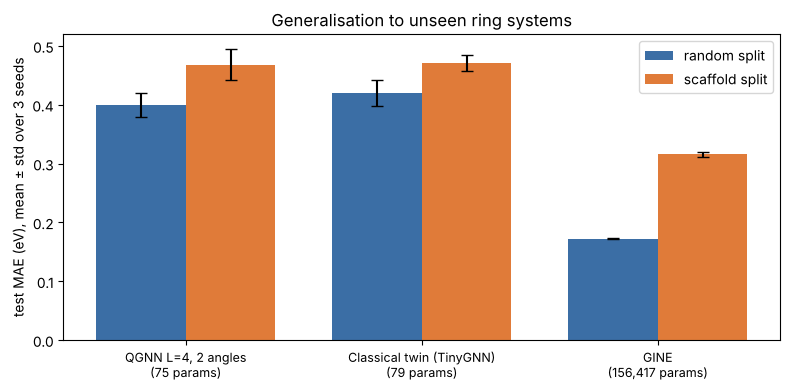

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(gen)); w = 0.38
ax.bar(x - w / 2, gen["random MAE"], w, yerr=gen["random std"], capsize=4, label="random split", color="#3b6ea5")
ax.bar(x + w / 2, gen["scaffold MAE"], w, yerr=gen["scaffold std"], capsize=4, label="scaffold split", color="#e07b39")
ax.set_xticks(x); ax.set_xticklabels([f"{m}\n({p:,} params)" for m, p in zip(gen.model, gen.params)], fontsize=9)
ax.set_ylabel("test MAE (eV), mean ± std over 3 seeds"); ax.legend()
ax.set_title("Generalisation to unseen ring systems")
plt.tight_layout(); plt.show()

## 3. Accuracy vs model size

Each point is one model trained on the 10k subset (random split), with the same test molecules. Unlabelled purple points are the other depths and ablations from section 4. The x-axis is on a log scale. The full-data GINE and the literature GCN are shown as reference lines.

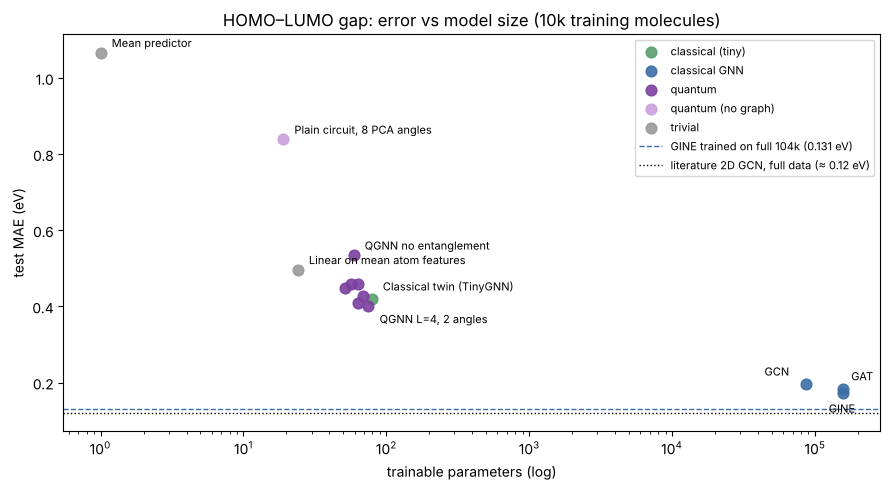

In [5]:
colors = {"quantum": "#7b3fa0", "quantum (no graph)": "#c9a0dc", "classical (tiny)": "#5a9e6f",
          "classical GNN": "#3b6ea5", "trivial": "#999999"}
pts = main[main.train_data == "10k subset"]
fig, ax = plt.subplots(figsize=(9, 5))
LABEL = {BEST_Q: (8, -12), "Classical twin (TinyGNN)": (8, 6), "QGNN no entanglement": (8, 4),
         "Plain circuit, 8 PCA angles": (8, 4), "Linear on mean atom features": (8, 4), "Mean predictor": (8, 4),
         "GINE": (-10, -14), "GCN": (-30, 6), "GAT": (6, 6)}
for fam, g in pts.groupby("family"):
    ax.scatter(g.params, g.test_mae_eV, s=60, color=colors[fam], label=fam, zorder=3, alpha=0.9)
    for _, r in g.iterrows():
        if r.model in LABEL:   # other depth / ablation variants are plotted but not labelled
            ax.annotate(r.model, (r.params, r.test_mae_eV), textcoords="offset points", xytext=LABEL[r.model], fontsize=8)
full = c[(c.train_data == "full 104k") & (c.test_set == "subset test")].test_mae_eV.mean()
ax.axhline(full, color="#3b6ea5", ls="--", lw=1, label=f"GINE trained on full 104k ({full:.3f} eV)")
ax.axhline(0.12, color="black", ls=":", lw=1, label="literature 2D GCN, full data (≈ 0.12 eV)")
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (log)"); ax.set_ylabel("test MAE (eV)")
ax.set_title("HOMO–LUMO gap: error vs model size (10k training molecules)")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 4. Quantum ablations

In [6]:
abl_names = [BEST_Q, "QGNN no entanglement", "QGNN bond-type blind", "Plain circuit, 8 PCA angles", "Classical twin (TinyGNN)"]
abl = q[(q.split == "random") & (q.seed == 0) & (q.model.isin(abl_names))].set_index("model").loc[abl_names]
abl[["params", "val_mae_eV", "test_mae_eV", "train_time_s"]].round(3)

,params,val_mae_eV,test_mae_eV,train_time_s
model,,,,
"QGNN L=4, 2 angles",75,0.377,0.379,153.253
QGNN no entanglement,59,0.543,0.535,114.463
QGNN bond-type blind,63,0.406,0.409,151.990
"Plain circuit, 8 PCA angles",19,0.839,0.839,80.432
Classical twin (TinyGNN),79,0.405,0.406,3.587


## 5. Caveats before reading the summary

- **Training budget:** the quantum GNN and the classical twin were capped at 25 epochs, and most runs were still improving when they stopped. The subset GINE runs were capped at 60 epochs and the full-data GINE at 30. Longer training would lower all of these numbers, the small models probably more than the GINE.
- **Fluorine on the scaffold split:** the scaffold test set happens to contain only **1** fluorine molecule (the random test set has 27), so the "with F" error on the scaffold split is not meaningful.
- **Ablations use one seed.** Seed-to-seed spread for the selected QGNN is about ±0.02 eV, so ablation differences smaller than that are not reliable. The entanglement and graph effects are much larger than that.

## 6. Summary

In [7]:
def get(model, split="random", data="10k subset"):
    return tab[(tab.model == model) & (tab.split == split) & (tab.train_data == data)].iloc[0]

g, qq, tw = get("GINE"), get(BEST_Q), get("Classical twin (TinyGNN)")
lin = get("Linear on mean atom features"); mean = get("Mean predictor")
gfull = c[(c.train_data == "full 104k") & (c.test_set == "full test (13,075)")].test_mae_eV.mean()
a = abl["test_mae_eV"]
out = [
    f"Best classical GNN (GINE, {g.params:,} params, 10k molecules): {g.test_mae_eV:.3f} ± {g['std']:.3f} eV.",
    f"Quantum GNN ({qq.params} params): {qq.test_mae_eV:.3f} ± {qq['std']:.3f} eV, "
    f"{qq.test_mae_eV / g.test_mae_eV:.1f}x the GINE error with {g.params / qq.params:,.0f}x fewer parameters.",
    f"Equal-size classical twin ({tw.params} params): {tw.test_mae_eV:.3f} ± {tw['std']:.3f} eV -> "
    + ("within seed-to-seed variation of the quantum GNN (a tie at equal size)."
       if abs(tw.test_mae_eV - qq.test_mae_eV) < max(tw['std'], qq['std'])
       else f"{'better than' if tw.test_mae_eV < qq.test_mae_eV else 'worse than'} the quantum GNN at the same size."),
    f"Trivial baselines: mean predictor {mean.test_mae_eV:.3f} eV, linear on mean atom features {lin.test_mae_eV:.3f} eV -> "
    f"the quantum GNN {'beats' if qq.test_mae_eV < lin.test_mae_eV else 'does not beat'} the linear baseline.",
    f"Entanglement: removing it changes test MAE from {a[BEST_Q]:.3f} to {a['QGNN no entanglement']:.3f} eV (seed 0).",
    f"Graph inside the circuit vs plain 8-PCA circuit: {a[BEST_Q]:.3f} vs {a['Plain circuit, 8 PCA angles']:.3f} eV.",
    f"Full-data GINE: {gfull:.3f} eV on the full test set (limited epochs; literature ≈ 0.12 eV).",
]
print("\n".join("• " + s for s in out))

• Best classical GNN (GINE, 156,417 params, 10k molecules): 0.173 ± 0.001 eV.
• Quantum GNN (75 params): 0.400 ± 0.020 eV, 2.3x the GINE error with 2,086x fewer parameters.
• Equal-size classical twin (79 params): 0.420 ± 0.022 eV -> within seed-to-seed variation of the quantum GNN (a tie at equal size).
• Trivial baselines: mean predictor 1.067 eV, linear on mean atom features 0.497 eV -> the quantum GNN beats the linear baseline.
• Entanglement: removing it changes test MAE from 0.379 to 0.535 eV (seed 0).
• Graph inside the circuit vs plain 8-PCA circuit: 0.379 vs 0.839 eV.
• Full-data GINE: 0.130 eV on the full test set (limited epochs; literature ≈ 0.12 eV).
